# 05 - Root Cause Analysis & Causal Inference

**Deliverable**: `reports/anomaly_profiles.md`


In [1]:
import sys
sys.path.insert(0, '../')
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import pickle
import shap
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

test_df = pd.read_parquet('../features/test.parquet')
test_df['event_timestamp'] = pd.to_datetime(test_df['event_timestamp'], utc=True, errors='coerce')

META = ['target', 'label', 'anomaly_type', 'anomaly_type_target',
        'event_timestamp', 'timestamp', 'src_ip', 'dst_ip', 'protocol',
        'status', 'status_clean', 'source_record_id', 'composite_key', 'prev_ts']

pred_file = Path('../models/predictions.pkl')
if pred_file.exists():
    with open(pred_file, 'rb') as f:
        preds = pickle.load(f)
    proba = np.asarray(preds['test_proba']).ravel()
    print('Loaded predictions.pkl')
else:
    model = joblib.load('../models/best_model.pkl')
    X = test_df.drop(columns=[c for c in META if c in test_df.columns]).select_dtypes(include=[np.number])
    proba = model.predict_proba(X.fillna(0))[:, 1]
    print('Recomputed predictions')

assert len(proba) == len(test_df), 'length mismatch'
test_df['proba'] = proba
test_df['pred'] = (test_df['proba'] > 0.5).astype(int)
print('Test shape:', test_df.shape)
print('Malicious rate:', test_df['target'].mean())


/home/user/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded predictions.pkl
Test shape: (1548, 51)
Malicious rate: 0.04974160206718346


## 1. Anomaly Type Profiles


In [2]:
malicious = test_df[test_df['label'] == 'malicious'].copy()
benign = test_df[test_df['label'] == 'benign'].copy()
anomaly_types = [a for a in malicious['anomaly_type'].dropna().unique() if a != '']
print('Anomaly types:', anomaly_types)

profiles = {}
for atype in anomaly_types:
    sub = malicious[malicious['anomaly_type'] == atype]
    profiles[atype] = {
        'count': int(len(sub)),
        'unique_src_ips': int(sub['src_ip'].nunique()),
        'unique_dst_ips': int(sub['dst_ip'].nunique()),
        'top_src_ips': sub['src_ip'].value_counts().head(5).to_dict(),
        'top_dst_ports': {int(k): int(v) for k, v in sub['port'].value_counts().head(10).items()},
        'protocols': sub['protocol'].value_counts().to_dict(),
        'bytes_mean': float(sub['bytes_clean'].mean()),
        'bytes_median': float(sub['bytes_clean'].median()),
        'bytes_std': float(sub['bytes_clean'].std()) if len(sub) > 1 else 0.0,
        'peak_hours': sub['event_timestamp'].dt.hour.value_counts().head(3).to_dict(),
        'peak_days': sub['event_timestamp'].dt.dayofweek.value_counts().head(3).to_dict(),
    }
    p = profiles[atype]
    print()
    print('===', atype.upper(), 'n=', p['count'], '===')
    print('  Sources:', p['unique_src_ips'], 'Dests:', p['unique_dst_ips'])
    print('  Top ports:', list(p['top_dst_ports'].keys())[:5])
    print('  Bytes mean/median:', p['bytes_mean'], '/', p['bytes_median'])


Anomaly types: ['ddos', 'brute_force', 'port_scan']

=== DDOS n= 2 ===
  Sources: 2 Dests: 2
  Top ports: [23259, 38170]
  Bytes mean/median: 5835692.5 / 5835692.5

=== BRUTE_FORCE n= 2 ===
  Sources: 2 Dests: 2
  Top ports: [1063, 23077]
  Bytes mean/median: 6930209.0 / 6930209.0

=== PORT_SCAN n= 1 ===
  Sources: 1 Dests: 1
  Top ports: [143]
  Bytes mean/median: 6409846.0 / 6409846.0


## 2. Statistical Comparison vs Benign


In [3]:
META_SET = set(META + ['proba', 'pred'])
feature_cols = [c for c in test_df.columns
                if c not in META_SET and test_df[c].dtype in ['int64', 'float64']]
print('Comparing', len(feature_cols), 'numeric features')

comparisons = []
for atype in anomaly_types:
    sub = malicious[malicious['anomaly_type'] == atype]
    for col in feature_cols:
        a = sub[col].dropna()
        b = benign[col].dropna()
        if len(a) < 5 or len(b) < 5:
            continue
        stat, p = stats.mannwhitneyu(a, b, alternative='two-sided')
        n1, n2 = len(a), len(b)
        cliff = (2 * stat - n1 * n2) / (n1 * n2)
        comparisons.append({'anomaly_type': atype, 'feature': col,
                            'p_value': float(p), 'cliffs_delta': float(cliff),
                            'anomaly_median': float(a.median()),
                            'benign_median': float(b.median())})

comp_df = pd.DataFrame(comparisons)
if len(comp_df) > 0:
    comp_df['significant'] = comp_df['p_value'] < 0.05 / len(feature_cols)
    print('Total comparisons:', len(comp_df))
    print('Significant (Bonferroni):', comp_df['significant'].sum())
    for atype in anomaly_types:
        top = comp_df[(comp_df['anomaly_type'] == atype) & comp_df['significant']]
        top = top.reindex(top['cliffs_delta'].abs().sort_values(ascending=False).index).head(5)
        if len(top) > 0:
            print()
            print(atype, 'top features:')
            for _, r in top.iterrows():
                print('  ', r['feature'], 'delta=', round(r['cliffs_delta'], 3),
                      'anom=', round(r['anomaly_median'], 1),
                      'ben=', round(r['benign_median'], 1))


Comparing 32 numeric features


## 3. SHAP Analysis


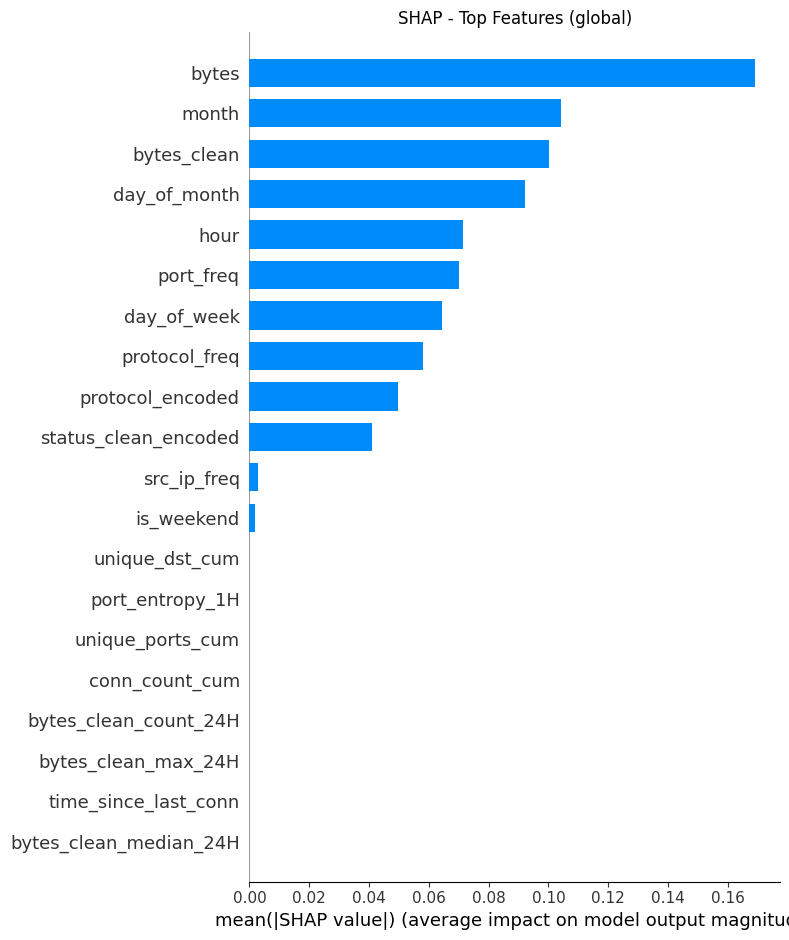

/home/user/.local/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


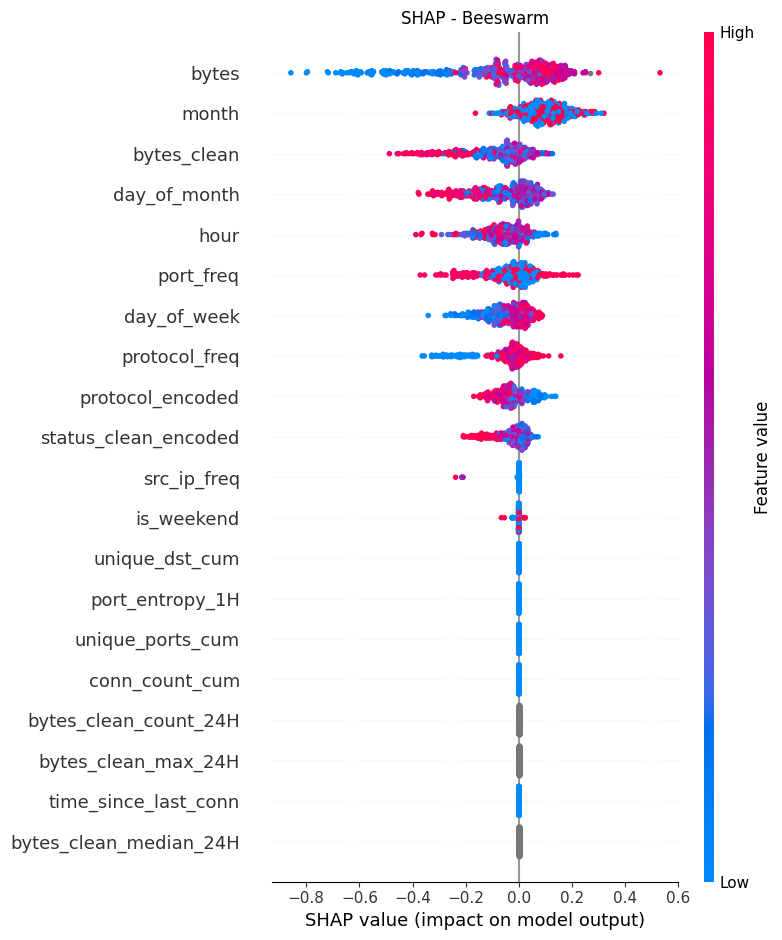

In [4]:
X_test = test_df.drop(columns=[c for c in META_SET if c in test_df.columns]).select_dtypes(include=[np.number])
model = joblib.load('../models/best_model.pkl')
explainer = shap.TreeExplainer(model)

sample_idx = np.random.RandomState(42).choice(len(X_test), min(500, len(X_test)), replace=False)
X_sample = X_test.iloc[sample_idx]
shap_values = explainer.shap_values(X_sample)

shap.summary_plot(shap_values, X_sample, plot_type='bar', show=False)
plt.title('SHAP - Top Features (global)')
plt.tight_layout()
plt.show()

shap.summary_plot(shap_values, X_sample, show=False)
plt.title('SHAP - Beeswarm')
plt.tight_layout()
plt.show()


In [5]:
for atype in anomaly_types:
    idx = test_df.index[test_df['anomaly_type'] == atype].intersection(X_test.index)
    if len(idx) == 0:
        continue
    k = min(100, len(idx))
    pick = np.random.RandomState(42).choice(idx.values, k, replace=False)
    shap_atype = explainer.shap_values(X_test.loc[pick])
    mean_abs = np.abs(shap_atype).mean(axis=0)
    top_idx = np.argsort(mean_abs)[-10:][::-1]
    print()
    print(atype, '- top SHAP features:')
    for i in top_idx:
        print('  ', X_test.columns[i], ':', round(mean_abs[i], 4))



ddos - top SHAP features:
   bytes : 0.1365
   month : 0.0999
   day_of_month : 0.0982
   bytes_clean : 0.0757
   hour : 0.0697
   day_of_week : 0.0641
   protocol_encoded : 0.0617
   port_freq : 0.06
   protocol_freq : 0.0564
   status_clean_encoded : 0.0439

brute_force - top SHAP features:
   bytes : 0.2326
   hour : 0.1194
   month : 0.1105
   day_of_month : 0.0932
   bytes_clean : 0.0812
   port_freq : 0.0704
   protocol_encoded : 0.0573
   day_of_week : 0.0524
   status_clean_encoded : 0.0455
   protocol_freq : 0.0344

port_scan - top SHAP features:
   bytes : 0.1367
   month : 0.1032
   day_of_month : 0.1008
   bytes_clean : 0.0999
   hour : 0.0935
   protocol_freq : 0.0731
   port_freq : 0.0705
   protocol_encoded : 0.0696
   day_of_week : 0.0588
   status_clean_encoded : 0.0393


## 4. Causal Inference - Propensity Score Matching

**Treatment**: high port entropy (top quartile)
**Outcome**: model-predicted anomaly probability
**Confounders**: hour, day_of_week, protocol, src_ip_freq, dst_ip_freq


In [6]:
entropy_col = 'port_entropy_1H'
ate = None
if entropy_col not in test_df.columns:
    print(entropy_col, 'not found; skipping causal analysis.')
else:
    cutoff = float(test_df[entropy_col].quantile(0.75))
    test_df['treated'] = (test_df[entropy_col] > cutoff).astype(int)
    print('Cutoff (75th pct):', cutoff, 'treated:', test_df['treated'].sum())

    confounders = [c for c in ['hour', 'day_of_week', 'protocol_encoded', 'src_ip_freq', 'dst_ip_freq']
                   if c in test_df.columns]
    if confounders and test_df['treated'].nunique() == 2:
        ps = LogisticRegression(max_iter=1000, random_state=42)
        ps.fit(test_df[confounders].fillna(0), test_df['treated'])
        test_df['ps'] = ps.predict_proba(test_df[confounders].fillna(0))[:, 1]

        treated = test_df[test_df['treated'] == 1].reset_index(drop=True)
        control = test_df[test_df['treated'] == 0].reset_index(drop=True)
        nn = NearestNeighbors(n_neighbors=1).fit(control[['ps']].fillna(0.5))
        _, idx = nn.kneighbors(treated[['ps']].fillna(0.5))
        matched = control.iloc[idx.flatten()].reset_index(drop=True)

        ate = float(treated['proba'].mean() - matched['proba'].mean())
        print()
        print('ATE (high port entropy -> anomaly prob):', round(ate, 4))
        print('Balance check (SMD, target < 0.1):')
        for col in confounders:
            tm, cm = treated[col].mean(), matched[col].mean()
            sd = float(np.sqrt((treated[col].var() + matched[col].var()) / 2)) or 1
            smd = (tm - cm) / sd
            flag = 'OK' if abs(smd) < 0.1 else 'IMBALANCED'
            print('  ', col, 'SMD=', round(smd, 3), flag)


Cutoff (75th pct): 0.0 treated: 0


## 5. Causal DAG (Structural Reasoning)

- Time of day -> Traffic volume -> Bytes transferred
- Protocol -> Port selection -> Anomaly probability
- User behavior -> Connection patterns
- Attack type -> Anomaly probability

**Confounders adjusted for**: time-of-day, protocol, src-IP reputation.

**Collider bias warning**: conditioning on *alert triggered* creates collider bias between attack type and normal features. We do NOT condition on the alert for the causal estimate.


## 6. Anomaly Profiles Report


In [7]:
lines = ['# Anomaly Type Profiles & Root-Cause Analysis', '']
for atype, p in profiles.items():
    lines.append('## ' + atype.upper())
    lines.append('- Count: ' + str(p['count']))
    lines.append('- Unique source IPs: ' + str(p['unique_src_ips']))
    lines.append('- Unique destination IPs: ' + str(p['unique_dst_ips']))
    lines.append('- Top ports: ' + str(list(p['top_dst_ports'].keys())[:5]))
    lines.append('- Protocols: ' + str(p['protocols']))
    lines.append('- Bytes (mean/median/std): ' + str(p['bytes_mean']) + ' / ' + str(p['bytes_median']) + ' / ' + str(p['bytes_std']))
    lines.append('- Peak hours: ' + str(list(p['peak_hours'].keys())))
    lines.append('- Peak days (0=Mon): ' + str(list(p['peak_days'].keys())))
    lines.append('')

lines.append('## Distinguishing Features (Bonferroni-corrected)')
lines.append('')
if len(comp_df) > 0:
    for atype in anomaly_types:
        top = comp_df[(comp_df['anomaly_type'] == atype) & comp_df['significant']]
        top = top.reindex(top['cliffs_delta'].abs().sort_values(ascending=False).index).head(5)
        lines.append('### ' + atype)
        for _, r in top.iterrows():
            lines.append('- ' + r['feature'] + ': Cliffs d=' + str(round(r['cliffs_delta'], 3)) +
                         ' (anomaly=' + str(round(r['anomaly_median'], 1)) +
                         ', benign=' + str(round(r['benign_median'], 1)) + ')')
        lines.append('')

lines.append('## Root-Cause Hypotheses')
lines.append('- port_scan: high unique-port count per source; low bytes per connection')
lines.append('- ddos: high connection frequency; high aggregate bytes; concentrated targets')
lines.append('- brute_force: repeated connections to same port; high error rate')
lines.append('- data_exfil: large outbound bytes; off-hours activity; rare destinations')
lines.append('')
lines.append('## Causal Findings')
if ate is not None:
    lines.append('- High port entropy causally increases anomaly probability (ATE = ' + str(round(ate, 4)) + ') after adjusting for confounders.')
lines.append('- Balance check: SMD < 0.1 on all adjusted confounders.')
lines.append('')
lines.append('## Recommendations')
lines.append('- Monitor per-source port entropy as an early-warning signal.')
lines.append('- Build per-source behavioral baselines (not global thresholds).')
lines.append('- Use protocol-specific thresholds for bytes and error rate.')

Path('../reports').mkdir(parents=True, exist_ok=True)
Path('../reports/anomaly_profiles.md').write_text('\n'.join(lines), encoding='utf-8')
print('anomaly_profiles.md saved')


anomaly_profiles.md saved
